In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Iris dataset
iris = load_iris()

# Convert the dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add the target species column
df["species"] = pd.Categorical.from_codes(
    iris.target, iris.target_names
)

# Display the first 5 records
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


In [8]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [10]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

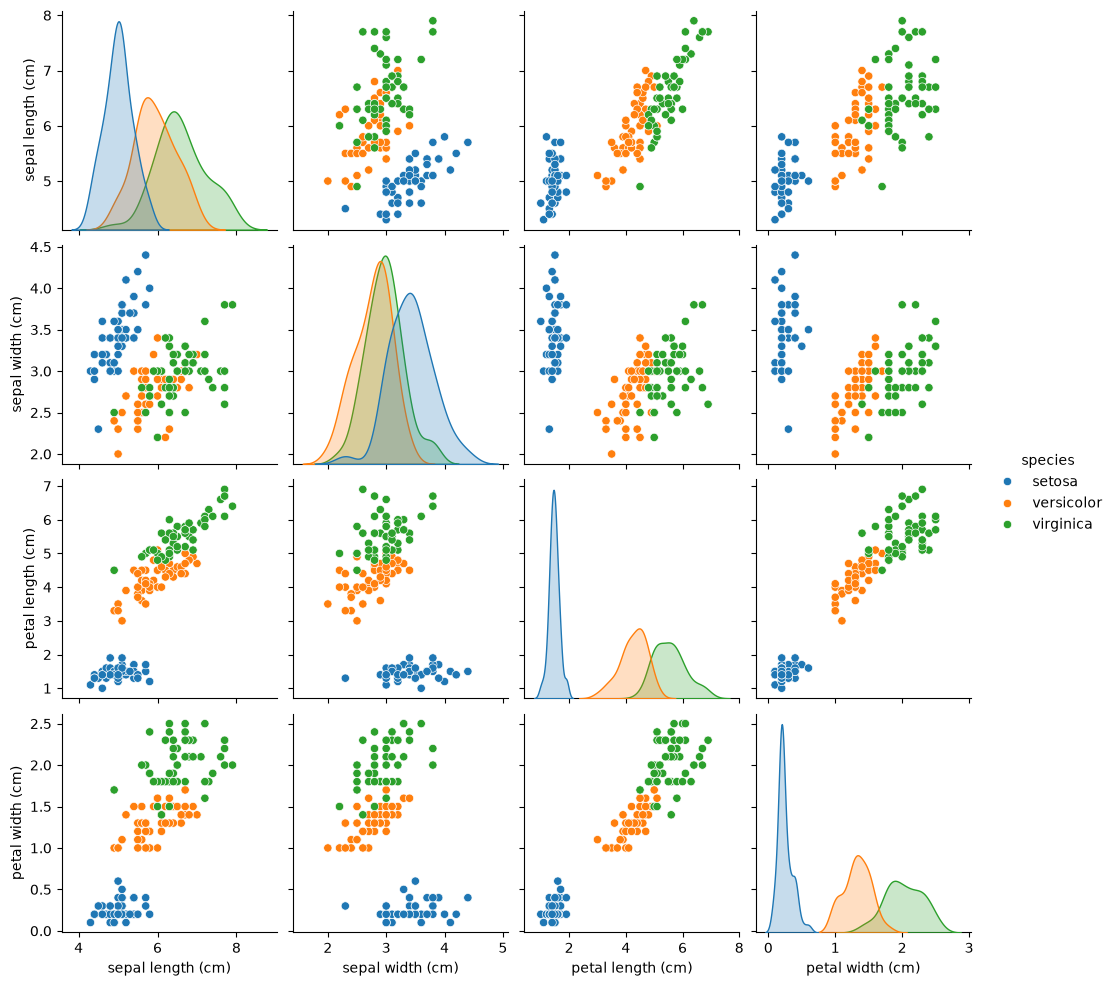

In [11]:
sns.pairplot(df, hue="species")
plt.show()

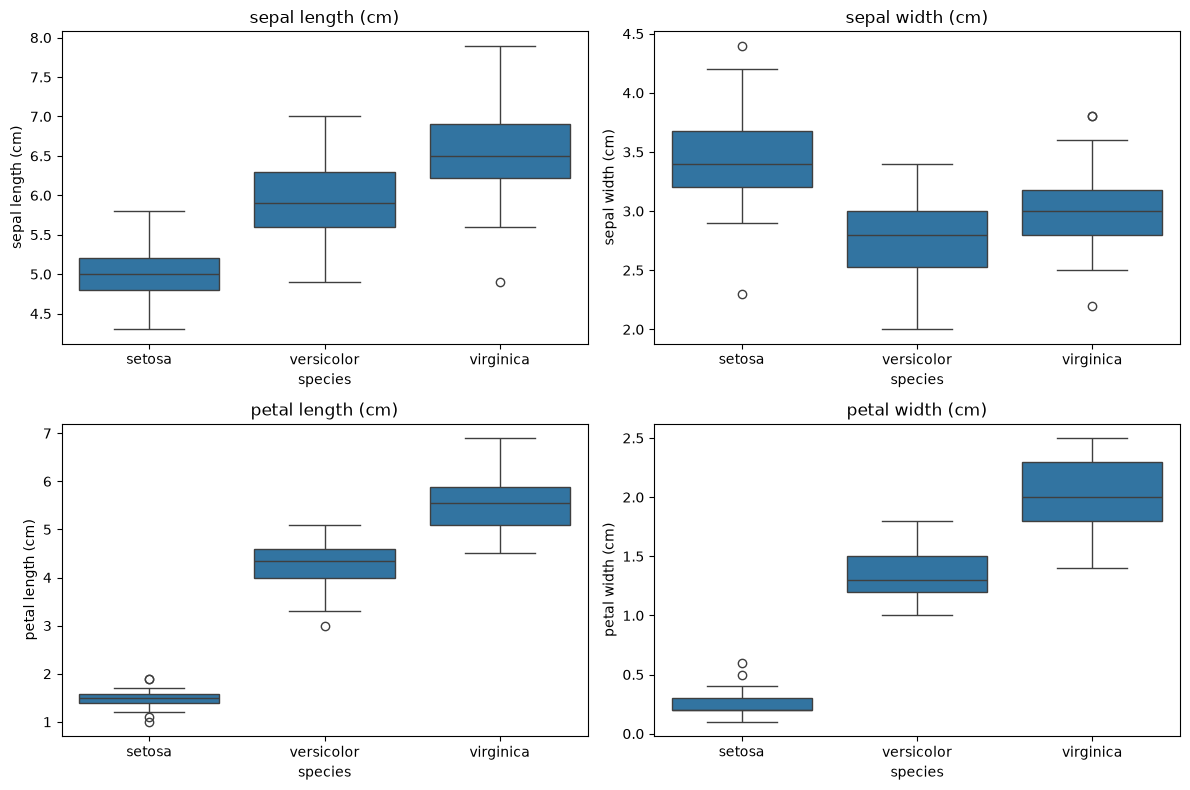

In [12]:
# Create boxplots for all four features

plt.figure(figsize=(12, 8))

for i, column in enumerate(iris.feature_names, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, x="species", y=column)
    plt.title(column)

plt.tight_layout()
plt.show()

In [13]:
# Separate input features and target variable

X = df.drop("species", axis=1)
y = df["species"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target variable:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: category
Categories (3, str): ['setosa', 'versicolor', 'virginica']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Create the models
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200)
)

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the models
log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [16]:
# Make predictions
log_predictions = log_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)

print("Logistic Regression Predictions:")
print(log_predictions)

print("\nKNN Predictions:")
print(knn_predictions)

Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

KNN Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']


In [17]:
from sklearn.metrics import accuracy_score

# Calculate accuracy
log_accuracy = accuracy_score(y_test, log_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print("Logistic Regression Accuracy:", log_accuracy * 100, "%")
print("KNN Accuracy:", knn_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %
KNN Accuracy: 93.33333333333333 %


In [18]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN"],
    "Accuracy": [log_accuracy, knn_accuracy]
})

results

,Model,Accuracy
0,Logistic Regression,0.933333
1,KNN,0.933333


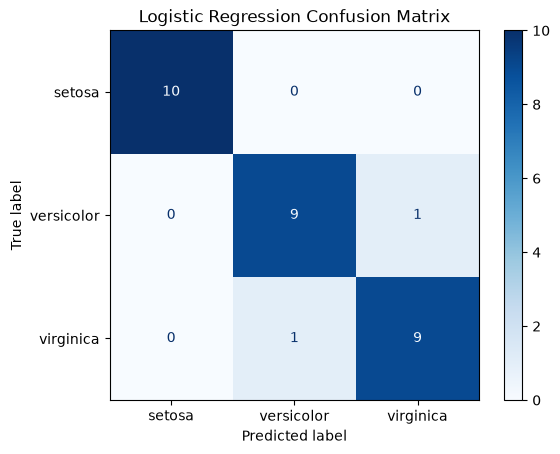

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, log_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

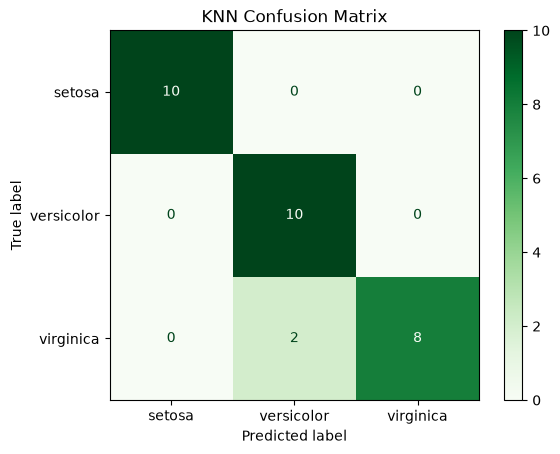

In [20]:
cm_knn = confusion_matrix(y_test, knn_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=iris.target_names
)

disp.plot(cmap="Greens")
plt.title("KNN Confusion Matrix")
plt.show()

In [21]:
from sklearn.metrics import classification_report

print("Logistic Regression Report:")
print(classification_report(y_test, log_predictions))

print("KNN Report:")
print(classification_report(y_test, knn_predictions))

Logistic Regression Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

KNN Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



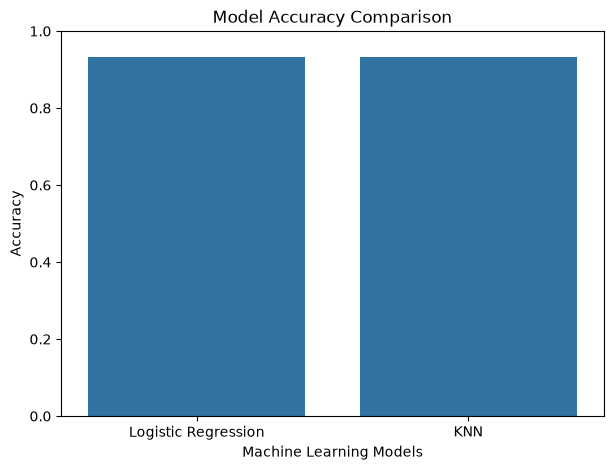

In [22]:
plt.figure(figsize=(7, 5))

sns.barplot(data=results, x="Model", y="Accuracy")

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)

plt.show()

## Conclusion

In this project, I developed an Iris Flower Classification model using Machine Learning techniques.

I performed Exploratory Data Analysis (EDA), checked missing values, analysed statistical summaries, and created visualisations using pairplots and boxplots.

I trained two classification algorithms: Logistic Regression and K-Nearest Neighbours (KNN). Both models achieved an accuracy of 93.33%.

Based on the classification reports, Logistic Regression was selected as the preferred model because it provided more balanced performance across all three flower species.

Through this project, I gained practical knowledge of data preprocessing, data visualisation, model training, and model evaluation.